# 09 · Risk diagnostics

## Purpose

This notebook extends the existing backtest by examining:

1. when dealer shortfalls and decision costs accumulate over time;
2. whether the model rules achieve their intended coverage;
3. whether underwater events cluster into consecutive periods.

The headline setting uses:

- a two-round purchase horizon (`h = 2`);
- a cost ratio of `k = 4`;
- the corresponding 80th percentile (`tau = 0.8`).

The main comparison covers:

- R0: no buffer;
- R1: fixed 5% buffer;
- R2: rolling-percentile rule (M1);
- R4: feature-based quantile regression (M3, the plan's main rule);
- R7: volatility-scaled rule (M6), the buffer model chosen on 2014–19 in notebook 05.

Confirmatory coverage results will focus on the untouched 2020–2026 test period.

In [1]:
import sys
import warnings
from pathlib import Path
from matplotlib.ticker import FuncFormatter

sys.path.insert(0, str(Path.cwd().parent))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.config import *
from src.backtest import rule_buffers
from src.plots import RULE_COLORS, save, sgd

pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

print("Project root:", ROOT)
print("Headline horizon:", H)

Project root: /Users/khushali/Documents/IS5126_Handson/Project/coe-guarantee
Headline horizon: 2


In [2]:
fc = pd.read_csv(PROC / "forecasts.csv")

EXTRA = {
    "R5 GBM (stretch)": "M4",
    "R6 Combo M1+M3": "M5",
    "R7 Vol-scaled": "M6",
}

bt = rule_buffers(fc, h=H, extra=EXTRA)

rule_counts = bt.groupby("rule").size()

print("Forecast rows:", len(fc))
print("Backtest rows:", len(bt))
print("Quote period:", bt["month"].min(), "to", bt["month"].max())
display(rule_counts)

Forecast rows: 157644
Backtest rows: 33972
Quote period: 2014-01 to 2026-09


rule
R0 No buffer              894
R1 Fixed 5%               894
R2 Rolling percentile    5364
R3 Newsvendor SARIMAX    5364
R4 Newsvendor QR         5364
R5 GBM (stretch)         5364
R6 Combo M1+M3           5364
R7 Vol-scaled            5364
dtype: int64

In [3]:
HEADLINE_TAU = 0.8
HEADLINE_K = 4

RULES = [
    "R0 No buffer",
    "R1 Fixed 5%",
    "R2 Rolling percentile",
    "R4 Newsvendor QR",
    "R7 Vol-scaled",
]

headline = bt[
    bt["rule"].isin(RULES)
    & (bt["tau"].isna() | (bt["tau"] == HEADLINE_TAU))
].copy()

headline["shortfall"] = (
    headline["actual_sgd"] - headline["buffer"]
).clip(lower=0)

headline["excess"] = (
    headline["buffer"] - headline["actual_sgd"]
).clip(lower=0)

headline["underwater"] = headline["shortfall"] > 0

headline["decision_cost"] = (
    headline["shortfall"]
    + headline["excess"] / HEADLINE_K
)

print("Selected rows:", len(headline))
print(headline.groupby("rule").size())

Selected rows: 4470
rule
R0 No buffer             894
R1 Fixed 5%              894
R2 Rolling percentile    894
R4 Newsvendor QR         894
R7 Vol-scaled            894
dtype: int64


In [4]:
summary = (
    headline.groupby("rule")
    .agg(
        n=("shortfall", "size"),
        underwater_pct=("underwater", lambda x: x.mean() * 100),
        avg_buffer=("buffer", "mean"),
        avg_shortfall_all_cars=("shortfall", "mean"),
        avg_excess=("excess", "mean"),
        avg_decision_cost=("decision_cost", "mean"),
    )
)

display(summary.round(1))

,n,underwater_pct,avg_buffer,avg_shortfall_all_cars,avg_excess,avg_decision_cost
rule,,,,,,
R0 No buffer,894,54.500,0.000,"2,370.200","2,010.800","2,872.900"
R1 Fixed 5%,894,27.700,"3,647.300",901.900,"4,189.800","1,949.300"
R2 Rolling percentile,894,19.400,"5,306.400",539.700,"5,486.800","1,911.400"
R4 Newsvendor QR,894,18.200,"5,612.200",536.900,"5,789.700","1,984.300"
R7 Vol-scaled,894,20.200,"4,992.000",650.300,"5,282.900","1,971.000"


## Cumulative risk over time

The overall averages do not show when losses occur. We therefore aggregate the
three simulated category sales within each quote round and calculate:

- cumulative dealer shortfall;
- cumulative newsvendor decision cost at `k = 4`;
- cumulative decision-cost savings relative to the fixed 5% rule.

These quantities are simulated backtest outcomes, not the dealer's actual accounting profit.

In [5]:
headline["quote_date"] = (
    pd.to_datetime(headline["month"] + "-01")
    + pd.to_timedelta(
        np.where(headline["bidding_no"] == 1, 6, 20),
        unit="D",
    )
)

roundly = (
    headline.groupby(
        ["rule", "round_id", "quote_date"],
        as_index=False,
    )
    .agg(
        shortfall=("shortfall", "sum"),
        excess=("excess", "sum"),
        decision_cost=("decision_cost", "sum"),
        underwater_sales=("underwater", "sum"),
        number_of_sales=("category", "size"),
    )
    .sort_values(["rule", "round_id"])
)

roundly["cum_shortfall"] = (
    roundly.groupby("rule")["shortfall"].cumsum()
)

roundly["cum_decision_cost"] = (
    roundly.groupby("rule")["decision_cost"].cumsum()
)

print("Rows per rule:")
display(roundly.groupby("rule").size())

print("First five rows:")
display(roundly.head())

Rows per rule:


rule
R0 No buffer             298
R1 Fixed 5%              298
R2 Rolling percentile    298
R4 Newsvendor QR         298
R7 Vol-scaled            298
dtype: int64

First five rows:


,rule,round_id,quote_date,shortfall,excess,decision_cost,underwater_sales,number_of_sales,cum_shortfall,cum_decision_cost
0,R0 No buffer,96,2014-01-07,0.000,"6,202.000","1,550.500",0,3,0.000,"1,550.500"
1,R0 No buffer,97,2014-01-21,"5,101.000",396.000,"5,200.000",2,3,"5,101.000","6,750.500"
2,R0 No buffer,98,2014-02-07,"15,842.000",0.000,"15,842.000",3,3,"20,943.000","22,592.500"
3,R0 No buffer,99,2014-02-21,"10,698.000",0.000,"10,698.000",3,3,"31,641.000","33,290.500"
4,R0 No buffer,100,2014-03-07,"6,295.000",0.000,"6,295.000",3,3,"37,936.000","39,585.500"


In [6]:
final_cumulative = (
    roundly.groupby("rule")
    .agg(
        total_shortfall=("shortfall", "sum"),
        total_excess=("excess", "sum"),
        total_decision_cost=("decision_cost", "sum"),
        underwater_sales=("underwater_sales", "sum"),
        total_sales=("number_of_sales", "sum"),
    )
)

final_cumulative["underwater_pct"] = (
    final_cumulative["underwater_sales"]
    / final_cumulative["total_sales"]
    * 100
)

display(final_cumulative.round(0))

,total_shortfall,total_excess,total_decision_cost,underwater_sales,total_sales,underwater_pct
rule,,,,,,
R0 No buffer,"2,118,938.000","1,797,688.000","2,568,360.000",487,894,54.000
R1 Fixed 5%,"806,282.000","3,745,677.000","1,742,701.000",248,894,28.000
R2 Rolling percentile,"482,535.000","4,905,162.000","1,708,825.000",173,894,19.000
R4 Newsvendor QR,"479,952.000","5,175,986.000","1,773,948.000",163,894,18.000
R7 Vol-scaled,"581,348.000","4,722,923.000","1,762,079.000",181,894,20.000


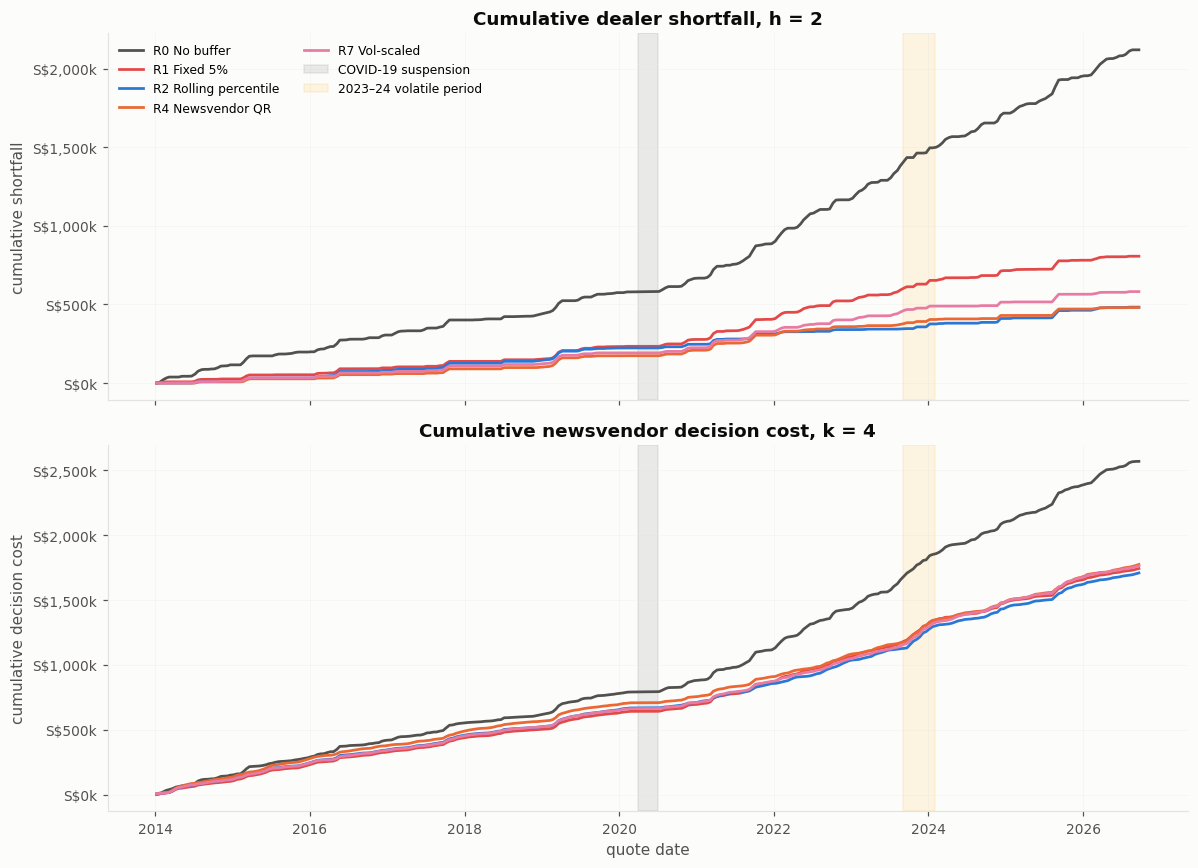

In [7]:
fig, axes = plt.subplots(
    2,
    1,
    figsize=(11, 8),
    sharex=True,
)

for rule in RULES:
    g = roundly[roundly["rule"] == rule]

    axes[0].plot(
        g["quote_date"],
        g["cum_shortfall"],
        label=rule,
        color=RULE_COLORS[rule],
        linewidth=1.8,
    )

    axes[1].plot(
        g["quote_date"],
        g["cum_decision_cost"],
        label=rule,
        color=RULE_COLORS[rule],
        linewidth=1.8,
    )

for ax in axes:
    # COVID-19 bidding suspension
    ax.axvspan(
        pd.Timestamp("2020-04-01"),
        pd.Timestamp("2020-07-01"),
        color="grey",
        alpha=0.15,
        label="COVID-19 suspension",
    )

    # Large premium movements around late 2023 / early 2024
    ax.axvspan(
        pd.Timestamp("2023-09-01"),
        pd.Timestamp("2024-02-01"),
        color="orange",
        alpha=0.10,
        label="2023–24 volatile period",
    )

    ax.grid(alpha=0.25)
    ax.yaxis.set_major_formatter(FuncFormatter(sgd))

axes[0].set_title(
    "Cumulative dealer shortfall, h = 2"
)
axes[0].set_ylabel("cumulative shortfall")

axes[1].set_title(
    "Cumulative newsvendor decision cost, k = 4"
)
axes[1].set_ylabel("cumulative decision cost")
axes[1].set_xlabel("quote date")

# Avoid duplicated shaded-area labels
handles, labels = axes[0].get_legend_handles_labels()
unique = dict(zip(labels, handles))
axes[0].legend(
    unique.values(),
    unique.keys(),
    loc="upper left",
    ncol=2,
    fontsize=8,
)

fig.tight_layout()
save(fig, "09_cumulative_risk.png")
plt.show()

## Cumulative decision-cost savings relative to a fixed 5% buffer

A positive value means that the model rule has accumulated a lower newsvendor
decision cost than the fixed 5% rule. A falling line means that the model rule
performed worse during that period.

The comparison uses the headline cost ratio `k = 4`.

In [8]:
cost_wide = (
    roundly.pivot(
        index=["round_id", "quote_date"],
        columns="rule",
        values="decision_cost",
    )
    .reset_index()
    .sort_values("round_id")
)

for rule in [
    "R0 No buffer",
    "R2 Rolling percentile",
    "R4 Newsvendor QR",
    "R7 Vol-scaled",
]:
    column_name = f"{rule}_saving_vs_R1"

    cost_wide[column_name] = (
        cost_wide["R1 Fixed 5%"]
        - cost_wide[rule]
    )

    cost_wide[f"cum_{column_name}"] = (
        cost_wide[column_name].cumsum()
    )

final_savings = pd.DataFrame(
    {
        "final_cumulative_saving_vs_R1": {
            rule: cost_wide[
                f"cum_{rule}_saving_vs_R1"
            ].iloc[-1]
            for rule in [
                "R0 No buffer",
                "R2 Rolling percentile",
                "R4 Newsvendor QR",
                "R7 Vol-scaled",
            ]
        }
    }
)

display(final_savings.round(0))

,final_cumulative_saving_vs_R1
R0 No buffer,"-825,659.000"
R2 Rolling percentile,"33,876.000"
R4 Newsvendor QR,"-31,247.000"
R7 Vol-scaled,"-19,377.000"


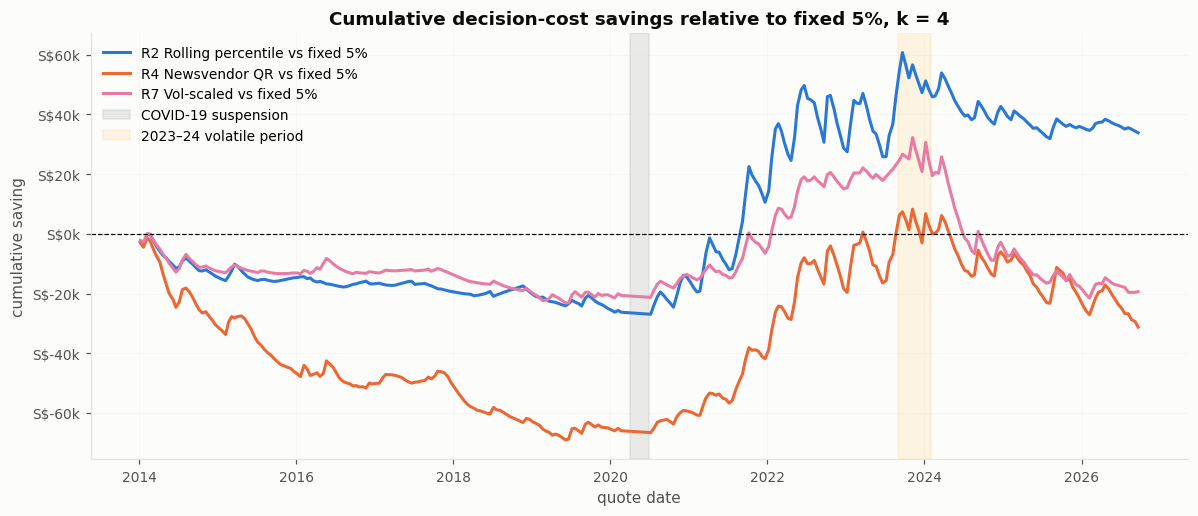

In [9]:
fig, ax = plt.subplots(figsize=(11, 4.8))

for rule in [
    "R2 Rolling percentile",
    "R4 Newsvendor QR",
    "R7 Vol-scaled",
]:
    ax.plot(
        cost_wide["quote_date"],
        cost_wide[f"cum_{rule}_saving_vs_R1"],
        label=f"{rule} vs fixed 5%",
        color=RULE_COLORS[rule],
        linewidth=2,
    )

ax.axhline(
    0,
    color="black",
    linewidth=0.8,
    linestyle="--",
)

ax.axvspan(
    pd.Timestamp("2020-04-01"),
    pd.Timestamp("2020-07-01"),
    color="grey",
    alpha=0.15,
    label="COVID-19 suspension",
)

ax.axvspan(
    pd.Timestamp("2023-09-01"),
    pd.Timestamp("2024-02-01"),
    color="orange",
    alpha=0.10,
    label="2023–24 volatile period",
)

ax.set_title(
    "Cumulative decision-cost savings relative to fixed 5%, k = 4"
)
ax.set_xlabel("quote date")
ax.set_ylabel("cumulative saving")
ax.yaxis.set_major_formatter(FuncFormatter(sgd))
ax.grid(alpha=0.25)
ax.legend(loc="best")

fig.tight_layout()
save(fig, "09_cumulative_saving_vs_fixed5.png")
plt.show()

In [10]:
period_cost = (
    headline.groupby(["period", "rule"])["decision_cost"]
    .sum()
    .unstack("rule")
)

period_comparison = pd.DataFrame(
    {
        "R1 Fixed 5% cost": period_cost["R1 Fixed 5%"],
        "R2 cost": period_cost["R2 Rolling percentile"],
        "R2 saving vs R1": (
            period_cost["R1 Fixed 5%"]
            - period_cost["R2 Rolling percentile"]
        ),
        "R4 cost": period_cost["R4 Newsvendor QR"],
        "R4 saving vs R1": (
            period_cost["R1 Fixed 5%"]
            - period_cost["R4 Newsvendor QR"]
        ),
        "R7 cost": period_cost["R7 Vol-scaled"],
        "R7 saving vs R1": (
            period_cost["R1 Fixed 5%"]
            - period_cost["R7 Vol-scaled"]
        ),
    }
)

display(period_comparison.round(0))

,R1 Fixed 5% cost,R2 cost,R2 saving vs R1,R4 cost,R4 saving vs R1,R7 cost,R7 saving vs R1
period,,,,,,,
2014-19,"627,822.000","652,806.000","-24,984.000","692,824.000","-65,001.000","648,237.000","-20,414.000"
2020-22,"433,125.000","379,358.000","53,766.000","386,441.000","46,684.000","397,635.000","35,489.000"
2023-26,"681,754.000","676,660.000","5,094.000","694,683.000","-12,929.000","716,207.000","-34,453.000"


## Kupiec unconditional coverage test

For a forecast quantile `tau`, an underwater event occurs when the actual
two-round COE rise exceeds the buffer.

At `tau = 0.8`, the expected underwater probability is:

\[
p_0 = 1 - \tau = 0.2.
\]

The Kupiec test evaluates:

\[
H_0: p = 0.2
\]

against the alternative that the true underwater probability differs from 0.2.

A p-value below 0.05 indicates that the observed underwater frequency is
inconsistent with the intended quantile coverage.

Formal tests are performed separately by COE category because categories in the
same bidding round may experience common market shocks.

*Caveat:* the test assumes independent outcomes, but neighbouring 2-round outcomes
overlap, so these p-values are approximate (too small if anything). A non-rejection,
as found below, is therefore conservative evidence of correct coverage.

In [11]:
from scipy.stats import chi2


def kupiec_test(exceptions, expected_exception_rate):
    """
    Kupiec unconditional coverage test.

    exceptions:
        Array containing 1 for underwater and 0 otherwise.

    expected_exception_rate:
        The intended probability of being underwater, equal to 1 - tau.
    """
    exceptions = np.asarray(exceptions, dtype=int)

    n = len(exceptions)
    x = int(exceptions.sum())

    if n == 0:
        return {
            "n": 0,
            "exceptions": 0,
            "expected_exceptions": np.nan,
            "exception_rate": np.nan,
            "lr_uc": np.nan,
            "p_value": np.nan,
        }

    p0 = expected_exception_rate
    p_hat = x / n

    # Avoid log(0) if there are zero or n exceptions.
    eps = 1e-12
    p_hat_safe = np.clip(p_hat, eps, 1 - eps)

    log_likelihood_null = (
        x * np.log(p0)
        + (n - x) * np.log(1 - p0)
    )

    log_likelihood_observed = (
        x * np.log(p_hat_safe)
        + (n - x) * np.log(1 - p_hat_safe)
    )

    lr_uc = -2 * (
        log_likelihood_null
        - log_likelihood_observed
    )

    p_value = chi2.sf(lr_uc, df=1)

    return {
        "n": n,
        "exceptions": x,
        "expected_exceptions": n * p0,
        "exception_rate": p_hat,
        "lr_uc": lr_uc,
        "p_value": p_value,
    }

In [12]:
COVERAGE_RULES = [
    "R2 Rolling percentile",
    "R4 Newsvendor QR",
    "R7 Vol-scaled",
]

coverage_data = bt[
    bt["rule"].isin(COVERAGE_RULES)
    & (bt["tau"] == HEADLINE_TAU)
].copy()

coverage_data["exception"] = (
    coverage_data["actual_sgd"]
    > coverage_data["buffer"]
).astype(int)

print("Rows by rule and category:")
display(
    coverage_data.groupby(["rule", "category"])
    .size()
    .unstack("category")
)

Rows by rule and category:


category,A,B,E
rule,,,
R2 Rolling percentile,298,298,298
R4 Newsvendor QR,298,298,298
R7 Vol-scaled,298,298,298


In [13]:
EXPECTED_EXCEPTION_RATE = 1 - HEADLINE_TAU

samples = {
    "Full 2014-26": coverage_data.index == coverage_data.index,
    "Test 2020-26": coverage_data["period"].isin(TEST_PERIODS),
}

kupiec_rows = []

for sample_name, sample_mask in samples.items():
    sample_data = coverage_data[sample_mask]

    for rule in COVERAGE_RULES:
        for category in ["A", "B", "E"]:
            g = sample_data[
                (sample_data["rule"] == rule)
                & (sample_data["category"] == category)
            ]

            result = kupiec_test(
                g["exception"],
                EXPECTED_EXCEPTION_RATE,
            )

            kupiec_rows.append(
                {
                    "sample": sample_name,
                    "rule": rule,
                    "category": category,
                    "tau": HEADLINE_TAU,
                    "target_exception_rate": EXPECTED_EXCEPTION_RATE,
                    **result,
                }
            )

kupiec_results = pd.DataFrame(kupiec_rows)

kupiec_results["exception_rate_pct"] = (
    kupiec_results["exception_rate"] * 100
)

kupiec_results["reject_5pct"] = (
    kupiec_results["p_value"] < 0.05
)

display(
    kupiec_results[
        [
            "sample",
            "rule",
            "category",
            "n",
            "exceptions",
            "expected_exceptions",
            "exception_rate_pct",
            "lr_uc",
            "p_value",
            "reject_5pct",
        ]
    ].round(3)
)

,sample,rule,category,n,exceptions,expected_exceptions,exception_rate_pct,lr_uc,p_value,reject_5pct
0,Full 2014-26,R2 Rolling percentile,A,298,57,59.600,19.128,0.143,0.705,False
1,Full 2014-26,R2 Rolling percentile,B,298,58,59.600,19.463,0.054,0.816,False
2,Full 2014-26,R2 Rolling percentile,E,298,58,59.600,19.463,0.054,0.816,False
3,Full 2014-26,R4 Newsvendor QR,A,298,51,59.600,17.114,1.612,0.204,False
4,Full 2014-26,R4 Newsvendor QR,B,298,54,59.600,18.121,0.674,0.412,False
5,Full 2014-26,R4 Newsvendor QR,E,298,58,59.600,19.463,0.054,0.816,False
6,Full 2014-26,R7 Vol-scaled,A,298,49,59.600,16.443,2.473,0.116,False
7,Full 2014-26,R7 Vol-scaled,B,298,61,59.600,20.470,0.041,0.840,False
8,Full 2014-26,R7 Vol-scaled,E,298,71,59.600,23.826,2.607,0.106,False
9,Test 2020-26,R2 Rolling percentile,A,154,31,30.800,20.130,0.002,0.968,False


In [14]:
kupiec_results.to_csv(
    PROC / "kupiec_coverage_tests.csv",
    index=False,
)

print(
    "Saved:",
    PROC / "kupiec_coverage_tests.csv",
)

Saved: /Users/khushali/Documents/IS5126_Handson/Project/coe-guarantee/data/processed/kupiec_coverage_tests.csv


## Christoffersen independence test

The Kupiec test checks whether the overall exception rate equals 20%.
The Christoffersen independence test checks whether exceptions cluster over time.

Because the forecast horizon is h = 2, adjacent forecast outcomes overlap.
We therefore split each category into two non-overlapping paths:
even-numbered and odd-numbered forecast origins.

In [15]:
def christoffersen_independence_test(exceptions):
    x = np.asarray(exceptions, dtype=int)

    if len(x) < 2:
        return {
            "n": len(x),
            "n00": np.nan,
            "n01": np.nan,
            "n10": np.nan,
            "n11": np.nan,
            "exception_after_safe_pct": np.nan,
            "exception_after_exception_pct": np.nan,
            "lr_ind": np.nan,
            "p_value": np.nan,
        }

    previous = x[:-1]
    current = x[1:]

    n00 = int(((previous == 0) & (current == 0)).sum())
    n01 = int(((previous == 0) & (current == 1)).sum())
    n10 = int(((previous == 1) & (current == 0)).sum())
    n11 = int(((previous == 1) & (current == 1)).sum())

    total_0 = n00 + n01
    total_1 = n10 + n11
    total = n00 + n01 + n10 + n11

    pi_0 = n01 / total_0 if total_0 > 0 else np.nan
    pi_1 = n11 / total_1 if total_1 > 0 else np.nan
    pi = (n01 + n11) / total if total > 0 else np.nan

    eps = 1e-12

    def log_term(count, probability):
        if count == 0:
            return 0.0
        probability = np.clip(probability, eps, 1 - eps)
        return count * np.log(probability)

    if np.isnan(pi_0) or np.isnan(pi_1):
        lr_ind = np.nan
        p_value = np.nan
    else:
        ll_independent = (
            log_term(n00 + n10, 1 - pi)
            + log_term(n01 + n11, pi)
        )

        ll_markov = (
            log_term(n00, 1 - pi_0)
            + log_term(n01, pi_0)
            + log_term(n10, 1 - pi_1)
            + log_term(n11, pi_1)
        )

        lr_ind = -2 * (ll_independent - ll_markov)
        p_value = chi2.sf(lr_ind, df=1)

    return {
        "n": len(x),
        "n00": n00,
        "n01": n01,
        "n10": n10,
        "n11": n11,
        "exception_after_safe_pct": pi_0 * 100,
        "exception_after_exception_pct": pi_1 * 100,
        "lr_ind": lr_ind,
        "p_value": p_value,
    }

In [16]:
christoffersen_rows = []

for sample_name, mask in samples.items():
    sample_data = coverage_data[mask].copy()

    for rule in COVERAGE_RULES:
        for category in ["A", "B", "E"]:
            g = (
                sample_data[
                    (sample_data.rule == rule)
                    & (sample_data.category == category)
                ]
                .sort_values("round_id")
                .copy()
            )

            g["path"] = g["round_id"].astype(int) % H

            for path in [0, 1]:
                path_data = g[g.path == path].sort_values("round_id")

                result = christoffersen_independence_test(
                    path_data.exception
                )

                christoffersen_rows.append({
                    "sample": sample_name,
                    "rule": rule,
                    "category": category,
                    "path": path,
                    **result,
                })

christoffersen_results = pd.DataFrame(christoffersen_rows)

christoffersen_results["reject_5pct"] = (
    christoffersen_results.p_value < 0.05
)

display(
    christoffersen_results.round(3)
)

christoffersen_results.to_csv(
    PROC / "christoffersen_independence_tests.csv",
    index=False
)

,sample,rule,category,path,n,n00,n01,n10,n11,exception_after_safe_pct,exception_after_exception_pct,lr_ind,p_value,reject_5pct
0,Full 2014-26,R2 Rolling percentile,A,0,149,90,26,26,6,22.414,18.750,0.204,0.652,False
1,Full 2014-26,R2 Rolling percentile,A,1,149,101,22,22,3,17.886,12.000,0.550,0.458,False
2,Full 2014-26,R2 Rolling percentile,B,0,149,90,25,25,8,21.739,24.242,0.091,0.762,False
3,Full 2014-26,R2 Rolling percentile,B,1,149,103,20,20,5,16.260,20.000,0.200,0.655,False
4,Full 2014-26,R2 Rolling percentile,E,0,149,88,25,25,10,22.124,28.571,0.597,0.440,False
5,Full 2014-26,R2 Rolling percentile,E,1,149,107,18,18,5,14.400,21.739,0.739,0.390,False
6,Full 2014-26,R4 Newsvendor QR,A,0,149,101,21,21,5,17.213,19.231,0.059,0.808,False
7,Full 2014-26,R4 Newsvendor QR,A,1,149,104,19,19,6,15.447,24.000,1.004,0.316,False
8,Full 2014-26,R4 Newsvendor QR,B,0,149,90,25,25,8,21.739,24.242,0.091,0.762,False
9,Full 2014-26,R4 Newsvendor QR,B,1,149,111,16,16,5,12.598,23.810,1.644,0.200,False


In [17]:
number_of_tests = len(christoffersen_results)

christoffersen_results["p_bonferroni"] = (
    christoffersen_results["p_value"] * number_of_tests
).clip(upper=1)

christoffersen_results["reject_bonferroni_5pct"] = (
    christoffersen_results["p_bonferroni"] < 0.05
)

significant_results = christoffersen_results[
    christoffersen_results["reject_5pct"]
][[
    "sample",
    "rule",
    "category",
    "path",
    "exception_after_safe_pct",
    "exception_after_exception_pct",
    "p_value",
    "p_bonferroni",
    "reject_bonferroni_5pct",
]]

display(significant_results.round(3))

,sample,rule,category,path,exception_after_safe_pct,exception_after_exception_pct,p_value,p_bonferroni,reject_bonferroni_5pct
11,Full 2014-26,R4 Newsvendor QR,E,1,12.295,42.308,0.001,0.030,True
29,Test 2020-26,R4 Newsvendor QR,E,1,14.754,40.000,0.039,1.000,False
30,Test 2020-26,R7 Vol-scaled,A,0,22.581,0.000,0.012,0.416,False


In [18]:
christoffersen_results.to_csv(
    PROC / "christoffersen_independence_tests.csv",
    index=False
)

print(
    "Saved:",
    PROC / "christoffersen_independence_tests.csv"
)

Saved: /Users/khushali/Documents/IS5126_Handson/Project/coe-guarantee/data/processed/christoffersen_independence_tests.csv


## Final findings

This notebook adds two risk diagnostics to the backtest in notebook 07.

### 1. Cumulative dealer risk

At the headline setting of \(h=2\), \(\tau=0.8\), and \(k=4\), over 894 simulated sales:

| Rule | Total shortfall | Total decision cost | Saving vs fixed 5% |
|---|---|---|---|
| R0 No buffer | S$2,118,938 | S$2,568,360 | −S$825,659 |
| R1 Fixed 5% | S$806,282 | S$1,742,701 | — |
| R2 Rolling percentile | S$482,535 | S$1,708,825 | +S$33,876 |
| R4 Newsvendor QR | S$479,952 | S$1,773,948 | −S$31,247 |
| R7 Vol-scaled (buffer model) | S$581,348 | S$1,762,079 | −S$19,377 |

R2 has the lowest cumulative decision cost, but the gaps between the model rules and fixed 5% are small: S$22–38 per car. They are within noise: the block-bootstrap intervals in notebook 07 are R2 [−156, +52] and R7 [−57, +97] per car at \(k=4\). The advantage is also not stable over time:

| Rule | 2014–19 | 2020–22 | 2023–26 |
|---|---|---|---|
| R2 vs fixed 5% | −S$24,984 | +S$53,766 | +S$5,094 |
| R7 vs fixed 5% | −S$20,414 | +S$35,489 | −S$34,453 |

All three model rules gain on fixed 5% only in the volatile 2020–22 period. R7's volatility-proportional buffers lost that gain again after the 2023–24 jumps. Every model rule keeps the dealer's cumulative shortfall far below fixed 5% and no buffer.

### 2. Unconditional coverage (Kupiec)

The Kupiec tests did not reject the target 20% exception rate for R2, R4 or R7 in any category, over either the full 2014–2026 sample or the 2020–2026 test period.

R7's Cat E exception rate is the highest: 23.8% over the full sample and 25.3% on the test period (p ≈ 0.11). This matches the report's finding that M6's buffer becomes too small when volatility is very low.

Because overlapping 2-round outcomes make the test approximate, these non-rejections show acceptable overall coverage. They do not, by themselves, show that exceptions were independent over time.

### 3. Exception clustering (Christoffersen)

Forecast origins were split into two non-overlapping paths before testing; there were 36 tests in all.

- **R2:** no significant clustering in any category.
- **R4, Category E, path 1:** evidence of clustering. Over 2014–2026 the exception probability was 12.3% after a safe outcome and 42.3% after an exception (p = 0.001, Bonferroni-adjusted p = 0.030). On the 2020–2026 test period alone it was 14.8% and 40.0% (p = 0.039, Bonferroni p = 1.000). This is a risk warning for R4 in Cat E, not proof that R4 always produces clustered losses.
- **R7:** one nominal rejection, Category A path 0 on the test period (p = 0.012, Bonferroni p = 0.42). It is in the opposite direction: no exception ever followed an exception. It is therefore not evidence of clustered losses.

### Overall conclusion

R2 (rolling percentile) and R7 (volatility-scaled, the buffer model chosen in notebook 05) both achieve about the target coverage, without detected clustering of losses. At \(k=4\) neither is significantly cheaper than fixed 5%, which agrees with the report: fixed 5% is close to optimal for a dealer whose \(k\) is about 2–4, and the forecasting models are statistically tied.

R4 is the only rule with a clustering warning, in Cat E.

These conclusions are conditional on the assumed cost ratio, the two-round purchase horizon and the historical backtest period. No rule should be described as universally superior under every dealer cost structure or market regime.